# Filters learnt in the pop-cosmos pre-training

The first two conv layers of the pre-trained `znn` model (`znn.load_pretrained("popcosmos")`). These two
layers are frozen when the model is fine-tuned on the challenge data, so every challenge model uses exactly
these filters.

- **Layer 1:** 32 filters. Each has kernel size 3 over the 3 input channels (the curve `m − m_i`, the bin
  position, the coverage), and outputs 32 values, one per wavelength bin.
- **Layer 2:** 64 filters, after a max-pooling that halves the grid. Each has kernel size 3 over the 32
  layer-1 channels, and outputs 16 values, one per pair of bins.

For each layer: the learnt weights, then each filter's output averaged over pop-cosmos galaxies.

In [25]:
import znn  # run from the repo root so this picks up the local source

PRETRAINING = "popcosmos"
MOCK_FILE = "mock_catalog_Ch1_26.h5"
FILTER_DIR = "data/popcosmos_filters"
I_MAX = 25.5  # as in the pre-training
N_SAMPLE = 50_000  # random subset of the galaxies passing the cut
SEED = 42
PLOT_DIR = "plots"

In [26]:
import os

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from matplotlib.ticker import MaxNLocator

from znn.data import make_lambda_bins

os.makedirs(PLOT_DIR, exist_ok=True)
BLUE = "#2a78d6"
um = 1e-4  # wavelengths are in Angstrom


def save(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f"{PRETRAINING}_filters_{name}.pdf"), bbox_inches="tight")


def grid(n, ncol=8, sharey=False):
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2 * ncol, 1.6 * nrow), sharex=True, sharey=sharey)
    for ax in axes.flat[n:]:
        ax.axis("off")
    return fig, axes.flat[:n]

In [27]:
pretrained, config, info = znn.load_pretrained(PRETRAINING)
model = pretrained[0][0]
conv1, conv2 = [layer for layer in model.layers if isinstance(layer, tf.keras.layers.Conv1D)][:2]
W1, W2 = conv1.get_weights()[0], conv2.get_weights()[0]  # (taps, in-channels, filters)
print("layer 1 kernels:", W1.shape, " layer 2 kernels:", W2.shape)

layer 1 kernels: (3, 3, 32)  layer 2 kernels: (3, 32, 64)


## Layer 1: weights

One panel per filter: its 3 taps (bluer bin, centre, redder bin), one line per input channel.

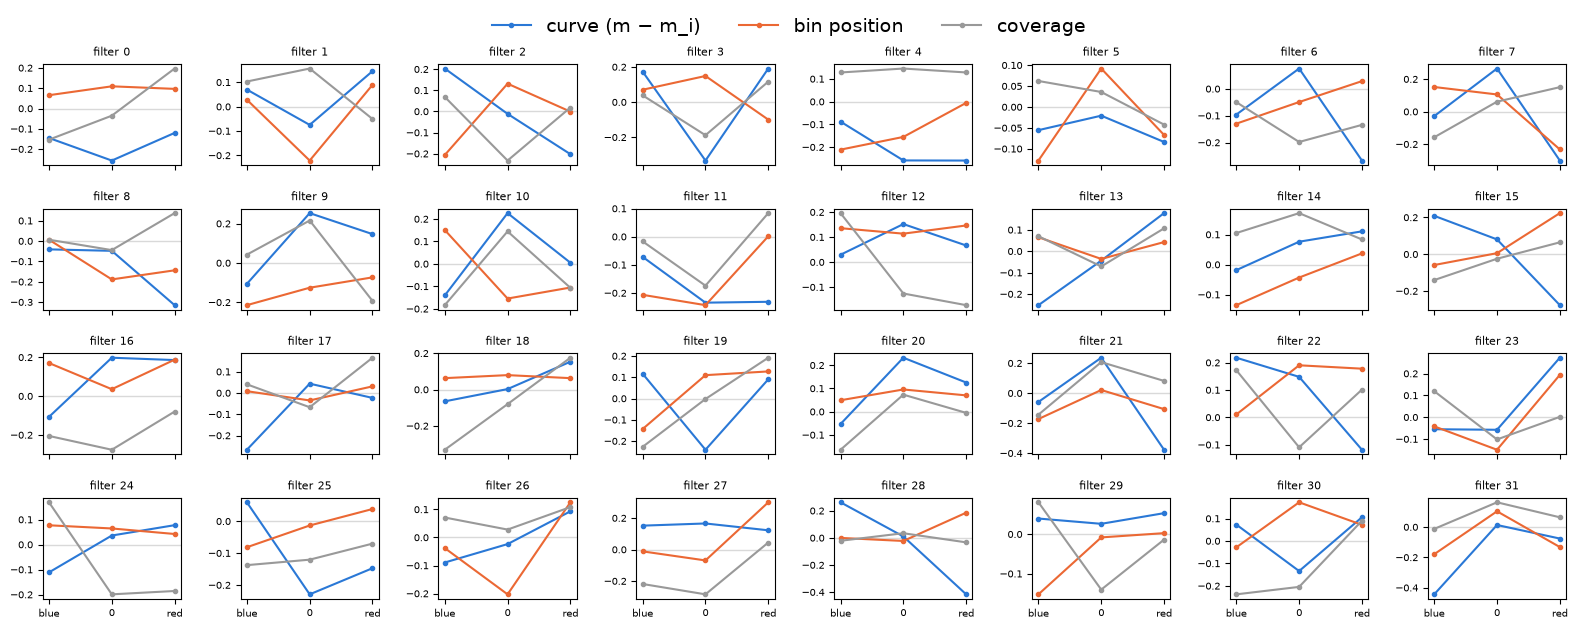

In [28]:
CHANNELS = {"curve (m − m_i)": "#2a78d6", "bin position": "#eb6834", "coverage": "0.6"}
taps = [-1, 0, 1]
fig, axes = grid(W1.shape[2])
for f, ax in enumerate(axes):
    for c, (label, color) in enumerate(CHANNELS.items()):
        ax.plot(taps, W1[:, c, f], "o-", color=color, lw=1.5, ms=3, label=label)
    ax.axhline(0, color="0.85", lw=1, zorder=0)
    ax.set_xticks(taps, ["blue", "0", "red"], fontsize=7)
    ax.tick_params(labelsize=7)
    ax.set_title(f"filter {f}", fontsize=8)
axes[0].figure.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.96))
save(fig, "layer1_weights")
plt.show()

## Layer 2: weights

One panel per filter: its 3 taps (bluer position, centre, redder position), one thin line per input
channel (the 32 layer-1 filters).

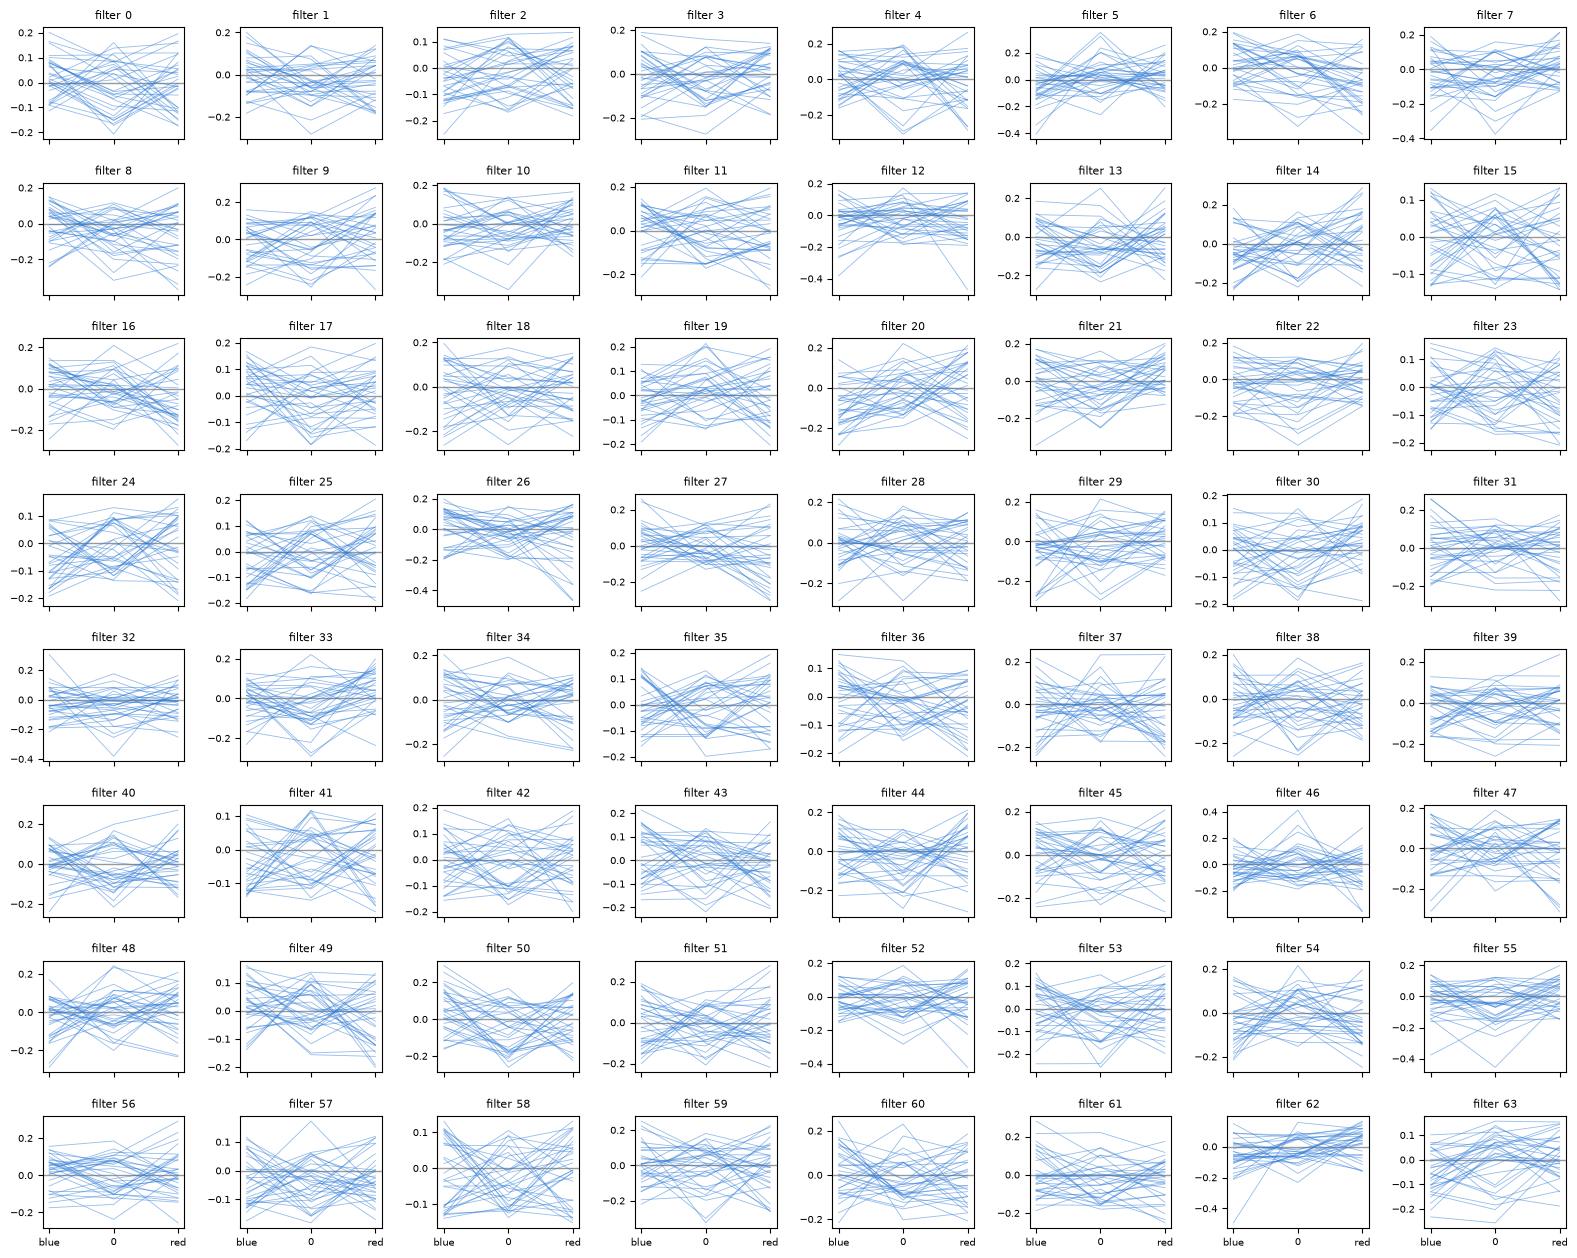

In [29]:
fig, axes = grid(W2.shape[2])
for f, ax in enumerate(axes):
    ax.plot(taps, W2[:, :, f], color=BLUE, lw=0.6, alpha=0.5)
    ax.axhline(0, color="0.6", lw=1, zorder=0)
    ax.set_xticks(taps, ["blue", "0", "red"], fontsize=7)
    ax.tick_params(labelsize=7)
    ax.set_title(f"filter {f}", fontsize=8)
fig.tight_layout()
save(fig, "layer2_weights")
plt.show()

## Outputs on pop-cosmos galaxies

The mock is encoded as in the pre-training: the 23 bands stored with the pre-trained model, its noisy
fluxes, i < 25.5 (filter files as in `popcosmos_encoding.ipynb`).

In [30]:
bands = info["training_data"]["bands"]
FILTER_FILES = {
    "u": "u_megaprime_sagem.res",
    **{b: f"hsc_{b}.res" for b in "griz"},
    "y": "hsc_y.par",
    **{b: f"uvista_{b.lower()}_cosmos.par" for b in "YJH"},
    **{b: f"ia{b[2:]}_cosmos.par" for b in bands if b.startswith(("IA", "IB"))},
    **{b: f"{b}.SuprimeCam.par" for b in bands if b.startswith("NB")},
}
BANDS = {b: (f"mag_{b}", f"{FILTER_DIR}/{FILTER_FILES[b]}") for b in bands}

with h5py.File(MOCK_FILE, "r") as f:
    columns = list(f.attrs["band_list"])
    fluxes = f["fluxes"][:]
    redshift = f["sps_parameters"][:, list(f.attrs["sps_parameter_list"]).index("z")]
with np.errstate(divide="ignore", invalid="ignore"):
    mags = np.where(fluxes > 0, -2.5 * np.log10(fluxes), np.nan)
keep = np.flatnonzero(mags[:, columns.index("i")] < I_MAX)
keep = np.sort(np.random.default_rng(SEED).choice(keep, min(N_SAMPLE, len(keep)), replace=False))
mock = pd.DataFrame({column: mags[keep, columns.index(b)] for b, (column, _) in BANDS.items()} | {"redshift": redshift[keep]})
del fluxes, mags

X, _ = znn.catalog_to_XY(mock, BANDS, "i", config)
out1, out2 = tf.keras.Model(model.inputs, [conv1.output, conv2.output]).predict(X, batch_size=8192, verbose=0)
print(f"{len(X):,} galaxies; layer 1 output {out1.shape[1:]}, layer 2 output {out2.shape[1:]}")

bin_centres, _ = make_lambda_bins(np.linspace(*config["lambda_range"], config["n_lambda"]), config["n_bins"])
wavelength = {1: bin_centres * um, 2: bin_centres.reshape(-1, 2).mean(axis=1) * um}  # layer 2 positions are pairs of bins


SILENT = 1e-3  # panels whose curves stay below this are drawn on a 0-1 scale and flagged


def plot_outputs(out, lam, name):
    # One panel per filter: mean output over the galaxies against observed wavelength, with its 16-84% range,
    # divided by the filter's peak (the larger of the two curves' maxima) so that all panels share one y axis
    lo, hi = np.percentile(out, [16, 84], axis=0)
    mean = out.mean(axis=0)
    # the 84th percentile is 0 for filters firing on few galaxies, hence the mean too
    peak = np.maximum(hi.max(axis=0), mean.max(axis=0))
    scale = np.where(peak >= SILENT, peak, 1.0)
    fig, axes = grid(out.shape[2], sharey=True)
    for f, ax in enumerate(axes):
        ax.fill_between(lam, lo[:, f] / scale[f], hi[:, f] / scale[f], color=BLUE, alpha=0.2, lw=0)
        ax.plot(lam, mean[:, f] / scale[f], color=BLUE, lw=1.5)
        ax.tick_params(labelsize=7)
        if peak[f] >= SILENT:
            label = f"filter {f}  ·  peak {peak[f]:.2g}"
        else:
            label = f"filter {f} ({'never' if out[:, :, f].max() == 0 else 'rarely'} fires)"
        ax.text(0.04, 0.94, label, transform=ax.transAxes, fontsize=8, va="top")
    ax.set_ylim(0, 1.3)  # headroom for the labels
    ax.yaxis.set_major_locator(MaxNLocator(3, prune="upper"))  # keep clear of the panel above
    for ax in axes[::8]:
        ax.set_ylabel("output / peak", fontsize=8)
    for ax in axes[-8:]:
        ax.set_xlabel("λ [µm]", fontsize=8)
    fig.tight_layout()
    fig.subplots_adjust(hspace=0.01, wspace=0)  # panels share their axes
    save(fig, name)
    plt.show()

50,000 galaxies; layer 1 output (32, 32), layer 2 output (16, 64)


## Layer 1: outputs

Each filter's output (after the ReLU) at the 32 wavelength bins: the mean over the galaxies, and the 16–84%
range. Each panel is divided by the filter's peak (the larger maximum of the two curves, given in
the label), so all panels share one y axis and show shapes, not sizes. Filters that never fire on these
galaxies, or whose peak stays below `SILENT`, are flagged and drawn unscaled.


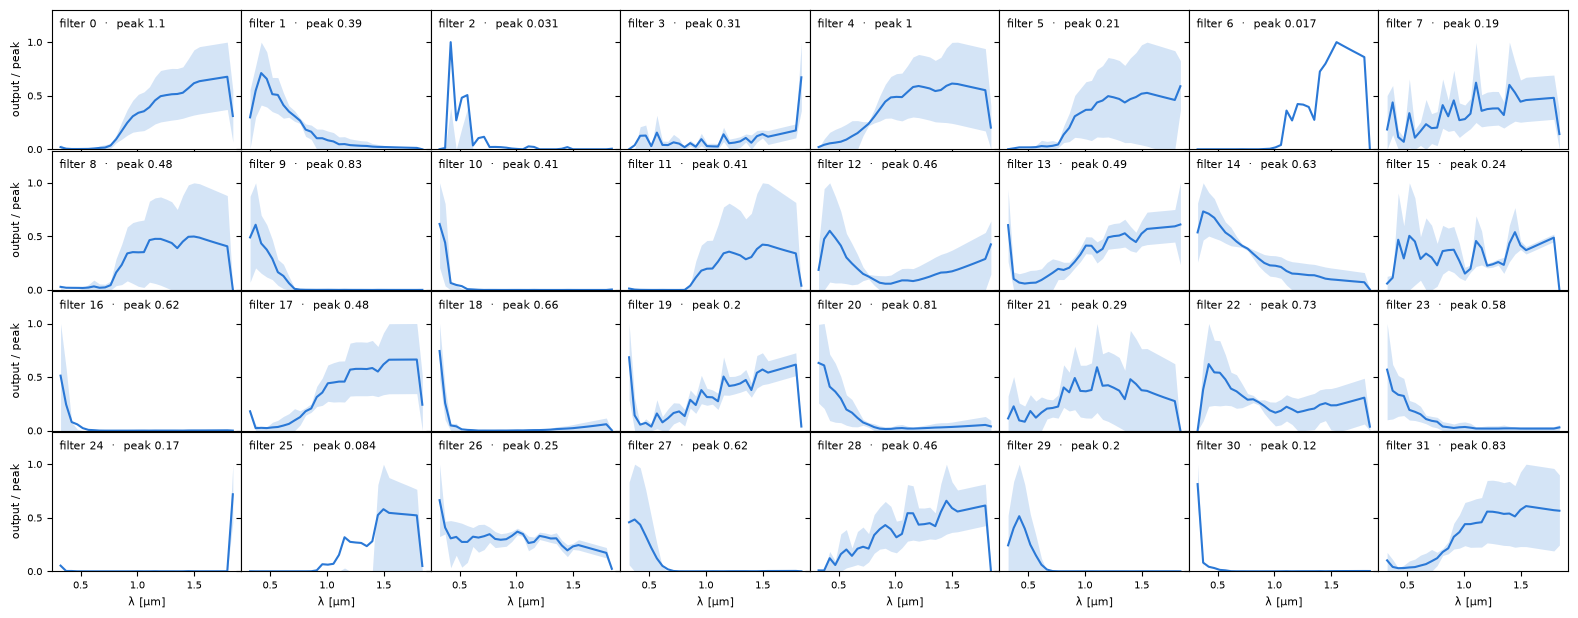

In [31]:
plot_outputs(out1, wavelength[1], "layer1_outputs")

## Layer 2: outputs

The same for the 64 layer-2 filters, at their 16 positions.

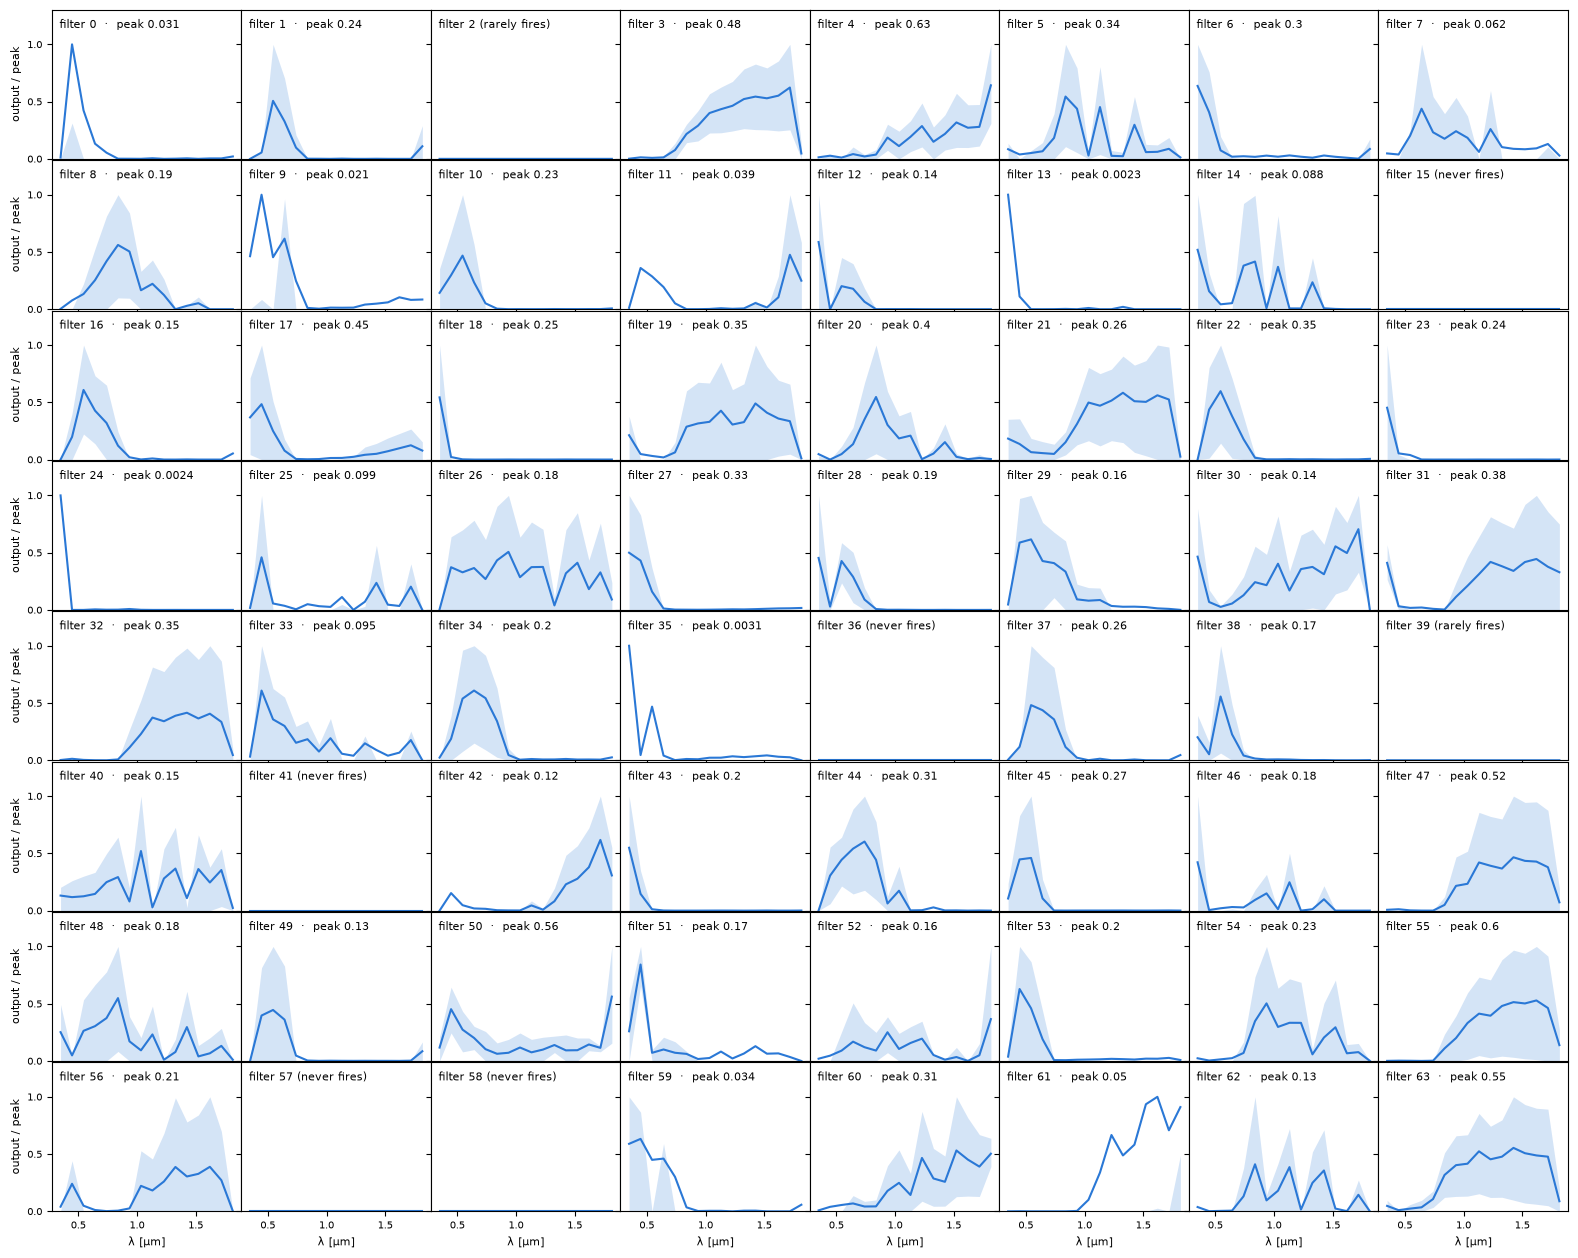

In [32]:
plot_outputs(out2, wavelength[2], "layer2_outputs")